<a href="https://colab.research.google.com/github/huynhtamtri2006-gif/TH---MACHINE_LEARNING/blob/main/B%C3%80I_T%E1%BA%ACP_L%E1%BB%9AP_REGRESSION/B%C3%A0i_t%E1%BA%ADp_h%E1%BB%93i_quy_Tu%E1%BA%A7n_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **BÀI TẬP LỚP**

**Bài 1.** Giả sử có một tập dữ liệu giả định với các cột Diện tích nhà (m2) và Giá bán (triệu VND).

1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên
Diện tích nhà.
2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.

**PHÂN TÍCH ĐỀ:**

- Đầu vào(X): Diện tích nhà (m2)
- Đầu ra (y): Giá bán (triệu VND)
- Nhiễu (b): b (b=200)
- Dữ liệu: Tự sinh dữ liệu ví dụ giá = b + w·diện_tích + nhiễu
- Mô hình Hồi quy tuyến tính (Linear Regression) với y^=w*x + b

**Câu 1: Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên Diện tích nhà.**



In [ ]:
#Cài thư viện cần thiết

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
#Xây dựng mô hình hồi quy qua tuyến tính đơn: Dựa trên giá bán theo diện tích

#Tạo dữ liệu giả định
#X là đầu vào (Diện tích nhà (X)), y là đầu ra (Giá bán (y))
np.random.seed(0)
X=30+120*np.random.randn(100,1) #diện tích từ 30 đến 150 m2
y=500+30*X+200*np.random.randn(100,1) #y = 500 + 30·X + nhiễu với b=500 và w=30

#Chia dữ liệu trên tập train và tập kiểm tra
X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2,random_state=42)

#Tạo Mô hình tuyến tính
model=LinearRegression()

#Huấn Luyện mô hình trên tập huấn luyện
model.fit(X_train,y_train)

#Dự đoán giá trên tập kiểm tra
y_pred=model.predict(X_test)

#Đánh giá mô hình
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

#In kết quả
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số góc (Slope): {model.coef_}")
print(f"Mean Squared Error (MSE): {mse}")
print(f"R^2 score: {r2}")

#Dự đoán thử giá nhà 80 m2
gia_80=model.predict([[80]])
print(f"Giá dự đoán nhà cho 80m2: {gia_80[0][0]} triệu VND")

Hệ số chặn (Intercept): [520.68008004]
Hệ số góc (Slope): [[30.06760732]]
Mean Squared Error (MSE): 55997.1242599746
R^2 score: 0.9959834980688551
Giá dự đoán nhà cho 80m2: 2926.0886654886535 triệu VND


# ↪ **Kết luận**
- **Slope ≈ 30.07:** mỗi m² tăng thêm làm giá tăng khoảng 30 triệu VND, gần như trùng hệ số thật (30).
- Intercept ≈ 520.68: lệch khoảng 21 triệu so với 500. Intercept lệch nhiều hơn slope vì nó là điểm cắt trục y, nằm xa vùng dữ liệu nên dễ bị nhiễu kéo lệch. Ở bài này nó không có ý nghĩa thực tế (không có nhà 0 m²).
- **R² = 0.996:** đường thẳng giải thích 99,6% sự biến thiên của giá. Con số cao vì dữ liệu được tạo đúng theo quan hệ tuyến tính, còn dữ liệu thật thường thấp hơn.
- **MSE = 55 997 (đơn vị triệu²):** lấy căn bậc hai được RMSE ≈ 237 triệu VND, tức dự đoán lệch trung bình khoảng 237 triệu. Con số này gần độ lệch chuẩn của nhiễu (200), nghĩa là mô hình đã đạt gần mức tốt nhất có thể.
- **Dự đoán 80 m² = 2926 triệu:** sát giá "lý tưởng" theo công thức thật (500 + 30×80 = 2900 triệu), lệch khoảng 0,9%.

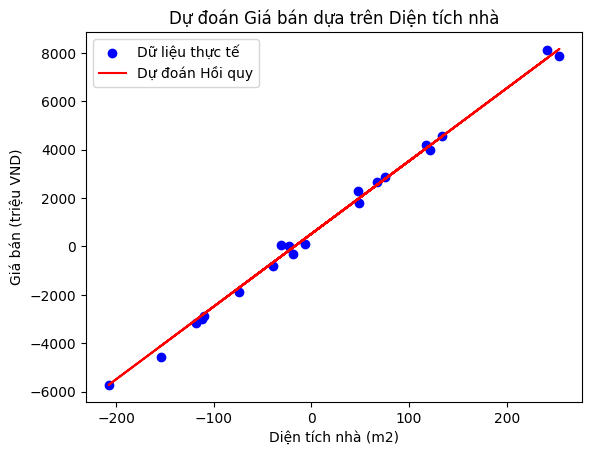

In [ ]:
#Vẽ biểu đồ dự đoán
plt.scatter(X_test,y_test,color='blue',label='Dữ liệu thực tế')
plt.plot(X_test,y_pred,color='red',label='Dự đoán Hồi quy')
plt.xlabel('Diện tích nhà (m2)')
plt.ylabel('Giá bán (triệu VND)')
plt.title('Dự đoán Giá bán dựa trên Diện tích nhà')
plt.legend()
plt.show()

**Câu 2: Thêm số lượng dữ liệu và độ nhiễu**

In [ ]:
#Thay đổi số lượng dữ liệu (n) và độ nhiễu để xem mô hình hoạt động thế nào
for n in [20,100,1000]:
    for nhieu in [50,200,500]:
        np.random.seed(0)
        x=30+120*np.random.rand(n,1)
        y=500+30*x+nhieu*np.random.randn(n,1)

        x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

        model=LinearRegression()
        model.fit(x_train,y_train)
        y_pred=model.predict(x_test)

        mse=mean_squared_error(y_test,y_pred)
        r2=r2_score(y_test,y_pred)

        print(f"n={n:5d} | nhiễu={nhieu:3d} | Intercept={model.intercept_[0]:8.2f} | Slope={model.coef_[0][0]:6.2f} | MSE={mse:10.2f} | R^2={r2:.3f}")

n=   20 | nhiễu= 50 | Intercept=  424.68 | Slope= 30.76 | MSE=   6378.11 | R^2=0.993
n=   20 | nhiễu=200 | Intercept=  198.71 | Slope= 33.04 | MSE= 102049.80 | R^2=0.877
n=   20 | nhiễu=500 | Intercept= -253.21 | Slope= 37.60 | MSE= 637811.27 | R^2=0.140
n=  100 | nhiễu= 50 | Intercept=  510.56 | Slope= 29.99 | MSE=   2294.38 | R^2=0.997
n=  100 | nhiễu=200 | Intercept=  542.24 | Slope= 29.97 | MSE=  36710.13 | R^2=0.948
n=  100 | nhiễu=500 | Intercept=  605.61 | Slope= 29.92 | MSE= 229438.31 | R^2=0.734
n= 1000 | nhiễu= 50 | Intercept=  507.47 | Slope= 29.93 | MSE=   1944.74 | R^2=0.998
n= 1000 | nhiễu=200 | Intercept=  529.88 | Slope= 29.71 | MSE=  31115.92 | R^2=0.971
n= 1000 | nhiễu=500 | Intercept=  574.70 | Slope= 29.27 | MSE= 194474.49 | R^2=0.848


# **↪ Kết luận**
- **Nhiễu tăng (cùng n):** MSE tăng mạnh, R² giảm. Ví dụ n = 100: R² giảm từ 0.997 (nhiễu 50) xuống 0.734 (nhiễu 500). Các điểm dữ liệu tản rộng quanh đường hồi quy nên dự đoán kém tin cậy hơn.
- **Dữ liệu ít (n = 20):** kết quả không ổn định. Ở nhiễu 500, slope lệch lên 37.6 (thật là 30), intercept thành số âm (-253) và R² chỉ còn 0.14. Tập test chỉ có 4 điểm nên các chỉ số cũng dao động nhiều.
- **Dữ liệu nhiều (n = 1000):** slope ổn định quanh 29–30 và R² cao hơn ở cùng mức nhiễu (nhiễu 500: R² từ 0.14 lên 0.848). Nhiều dữ liệu giúp mô hình "lọc" bớt nhiễu.
- **Giới hạn của việc thêm dữ liệu:** MSE không thể thấp hơn mức nhiễu vốn có (nhiễu² ≈ 2 500, 40 000, 250 000 cho 3 mức nhiễu). Thêm dữ liệu giúp hệ số ổn định, nhưng không xóa được nhiễu.

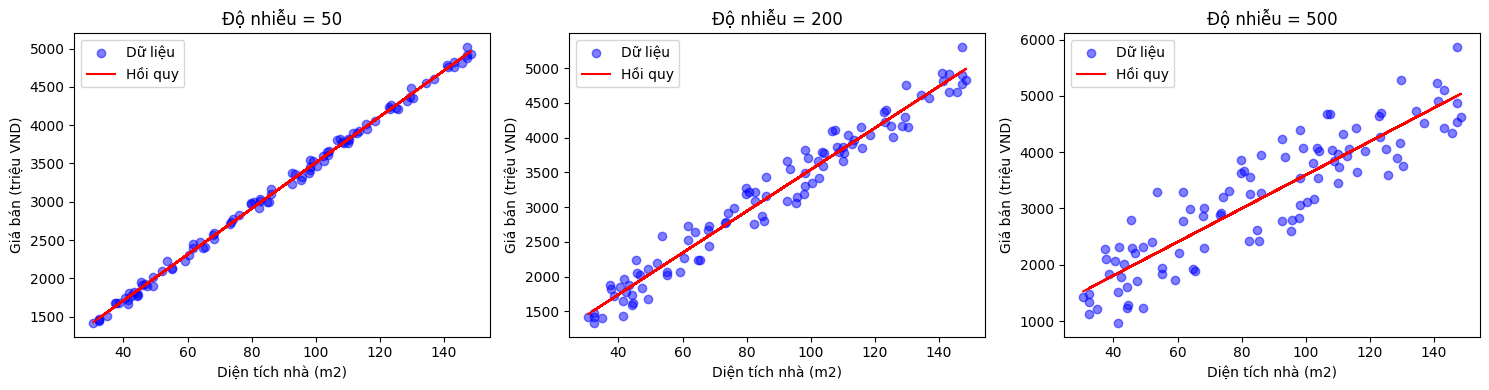

In [ ]:
#Vẽ biểu đồ so sánh các mức nhiễu (với n=100)
plt.figure(figsize=(15,4))
for i,nhieu in enumerate([50,200,500]):
    np.random.seed(0)
    x=30+120*np.random.rand(100,1)
    y=500+30*x+nhieu*np.random.randn(100,1)

    model=LinearRegression()
    model.fit(x,y)

    plt.subplot(1,3,i+1)
    plt.scatter(x,y,color='blue',alpha=0.5,label='Dữ liệu')
    plt.plot(x,model.predict(x),color='red',label='Hồi quy')
    plt.title(f'Độ nhiễu = {nhieu}')
    plt.xlabel('Diện tích nhà (m2)')
    plt.ylabel('Giá bán (triệu VND)')
    plt.legend()
plt.tight_layout()
plt.show()

Câu 3: Thêm các biến vào hồi quy (Hồi quy tuyến tính đa biến)

In [ ]:
#Tạo dữ liệu giả lập với nhiều biến đầu vào
#Cột 0: Diện tích (m2), Cột 1: Số phòng ngủ, Cột 2: Khoảng cách đến trung tâm (km), Cột 3: Tuổi nhà (năm)
np.random.seed(0)
n=300
dien_tich=30+120*np.random.rand(n)
so_phong=np.random.randint(1,6,n)
khoang_cach=1+19*np.random.rand(n)
tuoi_nha=np.random.randint(0,30,n)

X=np.column_stack((dien_tich,so_phong,khoang_cach,tuoi_nha)) #4 biến đầu vào
y=300+28*X[:,0]+80*X[:,1]-25*X[:,2]-10*X[:,3]+200*np.random.randn(n)

#Chia dữ liệu
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

#Mô hình 1 biến (chỉ dùng Diện tích) để so sánh
model_1=LinearRegression()
model_1.fit(X_train[:,[0]],y_train)
y_pred_1=model_1.predict(X_test[:,[0]])

#Mô hình nhiều biến
model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

#In kết quả
print("--- Mô hình 1 biến (Diện tích) ---")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test,y_pred_1)}")
print(f"R^2 score: {r2_score(y_test,y_pred_1)}")

print("--- Mô hình 4 biến ---")
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test,y_pred)}")
print(f"R^2 score: {r2_score(y_test,y_pred)}")

--- Mô hình 1 biến (Diện tích) ---
Mean Squared Error (MSE): 77414.08790551739
R^2 score: 0.9225104754873826
--- Mô hình 4 biến ---
Hệ số chặn (Intercept): 364.0278827279308
Hệ số hồi quy (Coefficients): [ 27.6974428   80.41861798 -27.5473522  -11.37111032]
Mean Squared Error (MSE): 41138.9301567039
R^2 score: 0.9588209817741253


Hệ số mô hình 4 biến (thứ tự: diện tích, số phòng ngủ, khoảng cách, tuổi nhà): 27.70, 80.42, -27.55, -11.37; Intercept = 364.

- **Mô hình tốt hơn:** MSE gần như giảm một nửa (77 414 → 41 139) và R² tăng từ 0.923 lên 0.959, vì các biến thêm vào cung cấp thêm thông tin giải thích giá.
- **Diện tích (+27.7) và số phòng ngủ (+80.4):** hệ số dương, tăng thì giá tăng. Thêm 1 phòng ngủ làm giá tăng khoảng 80 triệu khi các yếu tố khác giữ nguyên.
- **Khoảng cách (-27.5) và tuổi nhà (-11.4):** hệ số âm, nhà càng xa trung tâm hoặc càng cũ thì càng rẻ (mỗi km xa hơn giảm khoảng 27 triệu, mỗi năm tuổi giảm khoảng 11 triệu).
- **So với công thức thật (28, 80, -25, -10):** các hệ số rất gần. Intercept lệch hơn (364 so với 300) vì lý do tương tự câu 1.
- **Cách đọc hệ số:** mỗi hệ số là mức thay đổi của giá khi biến đó tăng 1 đơn vị, trong khi các biến còn lại giữ nguyên.

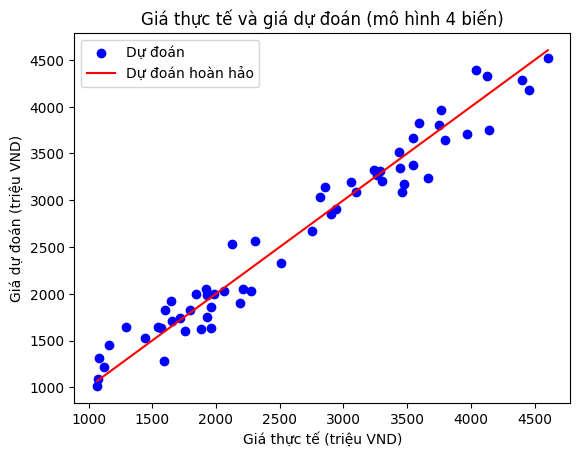

In [ ]:
#Vẽ biểu đồ giá thực tế và giá dự đoán
plt.scatter(y_test,y_pred,color='blue',label='Dự đoán')
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],color='red',label='Dự đoán hoàn hảo')
plt.title('Giá thực tế và giá dự đoán (mô hình 4 biến)')
plt.xlabel('Giá thực tế (triệu VND)')
plt.ylabel('Giá dự đoán (triệu VND)')
plt.legend()
plt.show()

 **Bài 2. Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI**

**Bài 2.** Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI
Giả sử có một tập dữ liệu với các thông tin sau:
- **BMI:** Chỉ số khối cơ thể của bệnh nhân (Body Mass Index).
- **Mắc bệnh:** Nhãn mục tiêu là 1 nếu bệnh nhân mắc bệnh và 0 nếu không mắc bệnh.
Yêu cầu:
1. Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn Mắc bệnh dựa trên mối liên hệ logic
(BMI cao có thể dẫn đến khả năng mắc bệnh cao hơn).
2. Sử dụng thư viện phù hợp (HD: scikit-learn) để xây dựng một mô hình hồi quy logistic.
3. Huấn luyện mô hình trên tập dữ liệu mẫu.
4. Dự đoán xác suất và nhãn mắc bệnh cho một tập dữ liệu kiểm tra.
5. Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn.
6. Trực quan hóa dữ liệu và đường hồi quy logistic.

**Phân tích bài toán:**

- **Đầu vào (X):** BMI chỉ số khối cơ thể bệnh nhân (Body Mass Index).
- **Đầu ra (y):** Mắc bệnh (0 và 1) - nhãn chỉ có "0 và 1" vì đây là bài `LogisticRegression`.
- **Đánh giá**:  Accuracy, ma trận nhầm lẫn

↪ Hồi quy logistic dùng `Hàm sigmoid` để biến kết quả tuyến tính thành xác suất


In [ ]:
#Thư viện cần thiết
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

**Câu 1: Tạo dữ liệu mẫu giả lập: BMI và nhãn Mắc bệnh**


In [ ]:
#Tạo dữ liệu giả định
#X là chỉ số BMI, y là nhãn mắc bệnh (1: Mắc bệnh, 0: Không mắc bệnh)
np.random.seed(0)
n=200
x=np.random.normal(25,5,(n,1)) #BMI trung bình 25, độ lệnh chuẩn 5
x=np.clip (x,15,40) #Giới hạn BMI trong khoảng 15 đến 40

#Xác suất mắc bệnh tăng dần khi BMI tăng (Hàm Sigmoid)
Xac_suat=1/(1+np.exp(-0.4*(x-27)))

#Gán nhãn ngẫu nhiên theo xác suất: BMI chiều cao càng dễ mắc bệnh
y=(np.random.rand(n,1)<Xac_suat).astype(int).ravel()

print(f"Số mẫu: {n}")
print(f"Số người mắc bệnh: {y.sum()} | Số người không mắc bệnh: {n-y.sum()}")

Số mẫu: 200
Số người mắc bệnh: 83 | Số người không mắc bệnh: 117


↪ **Dữ liệu:** 200 mẫu, 83 người "Mắc bênh" và 117 người "KHông mắc bệnh" ➡ **Accuracy có chỉ số phù hợp**

**Câu 2&3: Xây dựng mô hình hồi quy Logistic và Huấn luyện**

- **Xây mô hình:** `LogisticRegression()` của scikit-learn.
- **Huấn luyện:** chia train/test `80/20` rồi fit.

In [ ]:
#Chia dữ liệu thành tập huấn luyện và tập kiểm tra
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

#Tạo mô hình hồi quy Logistic
model=LogisticRegression()

#Huấn luyện mô hình
model.fit(x_train,y_train)

#In các tham số của mô hình
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số góc (Coeficient): {model.coef_}")
print(f"Ngưỡng BMI tại xác suất 50%: {-model.intercept_[0]/model.coef_[0][0]}")

Hệ số chặn (Intercept): [-8.17473173]
Hệ số góc (Coeficient): [[0.30626785]]
Ngưỡng BMI tại xác suất 50%: 26.691445954374522


**Tham số mô hình:** `Intercept = -8.17` và `Coeficient = 0.306`

- Hệ số **dương** nghĩa là BMI tăng thì xác suất mắc bệnh tăng, đúng với quan hệ ta thiết kế.
- Mỗi đơn vị BMI tăng thêm làm **log-odds** tăng 0.306, tức odds mắc bệnh nhân với e^0.306 ≈ 1.36 lần.
- **Ngưỡng BMI tại xác suất 50%** = -b/w ≈ 26.7, gần giá trị thật ta dùng khi sinh dữ liệu (27). BMI dưới ngưỡng này bị dự đoán không bệnh, trên ngưỡng bị dự đoán mắc bệnh.
- Hệ số 0.306 gần hệ số thật 0.4 nhưng thấp hơn, vì mô hình ước lượng từ dữ liệu có nhiễu ngẫu nhiên và chỉ 160 mẫu huấn luyện.

**Câu 4: Dự đoán xác suất và nhãn mắc bệnh trên tập kiểm tra**

In [ ]:
#Dự đoán xác suất (Cột 0: Không mắc bệnh, cột 1: mắc bệnh)
y_proba=model.predict_proba(x_test)

#Dự đoán nhãn (Ngưỡng 0.5)
y_pred=model.predict(x_test)

#In 10 mẫu đầu tiên
print("BMI   | Xác suất mắc bệnh | Dự đoán | Thực tế")
for i in range(10):
    print(f"{x_test[i][0]:5.1f} | {y_proba[i][1]:17.3f} | {y_pred[i]:7d} | {y_test[i]:7d}")

BMI   | Xác suất mắc bệnh | Dự đoán | Thực tế
 28.5 |             0.637 |       1 |       1
 26.7 |             0.498 |       0 |       0
 25.8 |             0.430 |       0 |       0
 19.3 |             0.093 |       0 |       0
 28.4 |             0.625 |       1 |       0
 29.0 |             0.671 |       1 |       1
 25.3 |             0.392 |       0 |       0
 29.6 |             0.709 |       1 |       0
 19.8 |             0.109 |       0 |       0
 22.8 |             0.233 |       0 |       1


**Dự đoán Xác suất (10 Mẫu):**

- **BMI 19.3** cho xác suất 0.093 → dự đoán không bệnh (đúng).
- **BMI 28.5** cho xác suất 0.637 → dự đoán mắc bệnh (đúng).
- **BMI 26.7** cho xác suất 0.498, sát ngưỡng 0.5 → dự đoán 0.
- **Có mẫu sai:** BMI 28.4 và 29.6 bị dự đoán mắc bệnh nhưng thực tế không bệnh; BMI 22.8 bị dự đoán không bệnh nhưng thực tế mắc bệnh. Những ca này sai do nhãn được sinh **ngẫu nhiên theo xác suất**: xác suất 0.7 vẫn có 30% là không bệnh, nên mô hình không thể đúng 100%.

**Câu 5: Đánh giá mô hình: Độ chính xác và Ma trận nhầm lẫn**

In [ ]:
#Độ chính xác
acc=accuracy_score(y_test,y_pred)
print(f"Độ chính xác (Accuracy): {acc}")

#Ma trận nhầm lẫn
cm=confusion_matrix(y_test,y_pred)
print("Ma trận nhầm lẫn:")
print(cm)
print(f"TN={cm[0][0]} | FP={cm[0][1]} | FN={cm[1][0]} | TP={cm[1][1]}")

Độ chính xác (Accuracy): 0.825
Ma trận nhầm lẫn:
[[24  4]
 [ 3  9]]
TN=24 | FP=4 | FN=3 | TP=9


**Độ chính xác = 0.825:** mô hình dự đoán đúng 82,5% trên tập kiểm tra (40 mẫu, đúng 33 mẫu).


**Ma trận nhầm lẫn** (hàng là thực tế, cột là dự đoán):

|  | Dự đoán không bệnh | Dự đoán mắc bệnh |
|---|---|---|
| **Thực tế không bệnh** | TN = 24 | FP = 4 |
| **Thực tế mắc bệnh** | FN = 3 | TP = 9 |

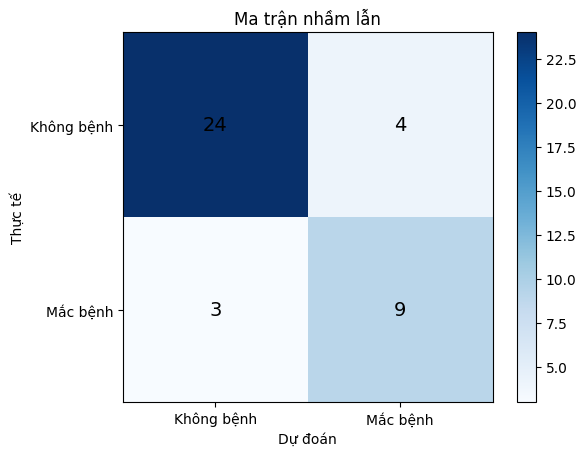

In [ ]:
#Vẽ ma trận nhầm lẫn
plt.imshow(cm,cmap='Blues')
plt.title('Ma trận nhầm lẫn')
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.xticks([0,1],['Không bệnh','Mắc bệnh'])
plt.yticks([0,1],['Không bệnh','Mắc bệnh'])
for i in range(2):
    for j in range(2):
        plt.text(j,i,cm[i][j],ha='center',va='center',fontsize=14)
plt.colorbar()
plt.show()

**Biểu đồ:** đường đỏ có dạng chữ S, thấp ở BMI nhỏ và cao ở BMI lớn, cắt đường ngưỡng 0.5 tại `BMI ≈ 26.7`. Vùng BMI quanh ngưỡng (khoảng 24–30) là nơi các điểm xanh lẫn lộn giữa hai nhãn, và cũng là nơi mô hình sai nhiều nhất.